# Part 4 · Reservoir forecasts

## Imports

In [ ]:
# Import the same code as Streamlit, from either the repository root or notebooks/.
import json
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from itertools import product
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from pymongo.errors import PyMongoError

from ind320.analysis.forecast import forecast_reservoir
from ind320.data.areas import export_reservoir_geojson
from ind320.data.exchange import fetch_exchange_rates
from ind320.data.reservoirs import fetch_reservoir_history
from ind320.data.weather import fetch_weather
from ind320.data.weeks import (
    OSLO, WEEK, combine_net_flows, cutoff_time, reservoir_weeks, rolling_weather_correlation,
    weather_week_range, weekly_flows, weekly_fx, weekly_weather,
)
from ind320.storage.mongo_store import query_months, query_weekly_flows

area = ("EL", 3)  # NVE area code for the NO3 price area.

2026-11-20 12:36:30.040 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-20 12:36:30.041 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## Putting the data on the same calendar

I line up NVE reservoir readings, ENTSO-E electricity flows, ERA5 weather, and Norges Bank exchange rates by Oslo weeks ending on Sunday. I check when each value is published so a forecast only uses information available on its start date. The Easter 2024 examples show how holidays and the clock change affect exchange rates and weather.

In [ ]:
# Easter 2024 includes business days, holidays and the spring DST transition.
easter_rates = fetch_exchange_rates("2024-03-25", "2024-04-03")
assert set(easter_rates.pair) == {"EUR/NOK", "USD/NOK"}
display(easter_rates.pivot(index="date", columns="pair", values="nok_per_unit"))
display(weekly_fx(easter_rates))

# Compare NVE's date-only label and next-release field with the joined ISO week.
raw_nve = fetch_reservoir_history()
nve = reservoir_weeks(raw_nve)
area_type, area_code = area
region = nve.loc[nve["Area Type"].eq(area_type) & nve["Area Code"].eq(area_code)]
easter_weeks = region.week.between("2024-03-24", "2024-04-07")
date_columns = ["Observation Date", "Iso Week", "Next Publication Date", "week", "available_at"]
display(region.loc[easter_weeks, date_columns])
filling = region.set_index("week")["Fill Level"] * 100

pair,EUR/NOK,USD/NOK
date,,
2024-03-25,11.6050,10.7107
2024-03-26,11.6260,10.7103
2024-03-27,11.6825,10.8011
2024-04-02,11.7080,10.8922
2024-04-03,11.6580,10.8115


nok_per_unit              available_at
week       pair                                           
2024-03-31 EUR/NOK       11.6825 2024-03-27 16:00:00+01:00
           USD/NOK       10.8011 2024-03-27 16:00:00+01:00
2024-04-07 EUR/NOK       11.6580 2024-04-03 16:00:00+02:00
           USD/NOK       10.8115 2024-04-03 16:00:00+02:00

2026-11-20 12:36:30.323 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-20 12:36:30.323 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,Observation Date,Iso Week,Next Publication Date,week,available_at
13718,2024-03-24,12,2024-04-03 13:00:00,2024-03-24,2024-03-27 13:00:00+01:00
13727,2024-03-31,13,2024-04-10 13:00:00,2024-03-31,2024-04-03 13:00:00+02:00
13736,2024-04-07,14,2024-04-17 13:00:00,2024-04-07,2024-04-10 13:00:00+02:00


In [ ]:
# Use one ERA5 grid point to show how UTC timestamps map to Oslo weeks.
response = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params={
        "latitude": 63.5,
        "longitude": 10.25,
        "start_date": "2024-03-24",
        "end_date": "2024-04-01",
        "timezone": "UTC",
        "models": "era5",
        "hourly": "temperature_2m,precipitation",
        "elevation": "nan",
        "cell_selection": "nearest",
    },
    timeout=30,
)
response.raise_for_status()
weather_sample = pd.DataFrame(response.json()["hourly"])
display(weather_sample.iloc[[0, 167, 168]])
weather_sample.index = pd.to_datetime(weather_sample.pop("time"), utc=True)
display(weekly_weather(weather_sample))

,time,precipitation,temperature_2m
0,2024-03-24T00:00,0.0,-0.4
167,2024-03-30T23:00,0.0,4.2
168,2024-03-31T00:00,0.0,4.1


,temperature_2m,precipitation,available_at
week,,,
2024-03-31,4.180838,5.9,2024-04-06 00:00:00+02:00


In [ ]:
# Use the Part 2 export if MongoDB has no data or cannot be reached.
border = "NO3–SE2"
months = list(range(1, 13))
try:
    intervals = pd.concat(
        [query_months(border, year, months) for year in (2024, 2025)],
        ignore_index=True,
    )
    flow_source = "MongoDB transfer_intervals"
except PyMongoError:
    intervals = pd.DataFrame()
    flow_source = "MongoDB unavailable"
saved_transfers = root / ".local" / "transfers.pkl"
if intervals.empty and saved_transfers.is_file():
    saved = pd.read_pickle(saved_transfers)
    intervals = saved.loc[saved.connection.eq(border)].copy()
    flow_source = "local Part 2 ENTSO-E archive export"

flow = weekly_flows(intervals)
print(f"{flow_source}. Complete weeks for {border}: {len(flow)}.")
if not intervals.empty:
    sample = intervals[["direction", "start", "end"]].head(2).copy()
    sample["start_oslo"] = sample.start.dt.tz_convert(OSLO)
    display(sample)
    display(flow.head(2))

MongoDB transfer_intervals. Complete weeks for NO3–SE2: 104.


,direction,start,end,start_oslo
0,export,2023-12-31 23:00:00+00:00,2024-01-02 09:00:00+00:00,2024-01-01 00:00:00+01:00
1,export,2024-01-02 09:00:00+00:00,2024-01-02 10:00:00+00:00,2024-01-02 10:00:00+01:00


,net_import_mwh,available_at
week,,
2024-01-07,5182.75,2024-01-08 01:00:00+01:00
2024-01-14,46589.24,2024-01-15 01:00:00+01:00


## Choosing a forecast model

I compare 13-week River SNARIMAX forecasts using different model settings, lengths of filling history, and exchange-rate inputs. Each run uses data available at its start date and carries the latest available input values forward. River updates its regression one week at a time, with a seasonal lag of 52 weeks. I use 2023 and 2024 to pick the settings, save 2025 for testing, and compare against the observed filling from 52 weeks earlier to see if the model beats a simple benchmark.


In [ ]:
# Prepare sufficient FX history for the longest lookback and every origin.
fx = weekly_fx(fetch_exchange_rates("2019-12-01", "2025-12-31"))
exchange_pairs = ("EUR/NOK", "USD/NOK")
sources = {
    pair: fx.xs(pair, level="pair").rename(columns={"nok_per_unit": pair})
    for pair in exchange_pairs
}

def forecast_dates(year: int) -> list[pd.Timestamp]:
    # Pick the second Wednesday of each selected month.
    return [
        pd.date_range(f"{year}-{month:02d}-01", periods=2, freq="W-WED")[1]
        for month in (1, 4, 7, 9)
    ]

def evaluate(
    dates: list[pd.Timestamp],
    order: tuple[int, int, int],
    training_weeks: int,
    inputs: tuple[str, ...] = (),
    bands: bool = False,
) -> pd.DataFrame:
    # Fit at each cutoff and join the observed filling levels for scoring.
    trials = []
    for origin in dates:
        cutoff = cutoff_time(origin)
        started_at = perf_counter()
        predictions = forecast_reservoir(
            nve, sources, area=area, cutoff=cutoff, training_weeks=training_weeks,
            horizon=13, order=order, selected_inputs=inputs, intervals=bands,
        )
        elapsed_ms = (perf_counter() - started_at) * 1000
        # The benchmark also uses only readings published by this cutoff.
        known_weeks = region.loc[region.available_at.le(cutoff), "week"]
        last_year = filling.loc[known_weeks].reindex(predictions.index - 52 * WEEK)
        trials.append(predictions.assign(
            actual=filling.reindex(predictions.index),
            seasonal_naive=last_year.to_numpy(),
            origin=origin,
            runtime_ms=elapsed_ms,
        ))
    return pd.concat(trials)

def scores(trials: pd.DataFrame, column: str) -> tuple[float, float]:
    errors = trials[column] - trials.actual
    return errors.abs().mean(), np.sqrt(errors.pow(2).mean())

tuning_dates = forecast_dates(2023) + forecast_dates(2024)
rows = []
orders = [(1, 1, 0), (4, 1, 0), (2, 1, 1)]
lookbacks = [104, 156]
for order, weeks, inputs in product(orders, lookbacks, [(), exchange_pairs]):
    # Keep settings that produce forecasts at all eight tuning dates.
    try:
        trials = evaluate(tuning_dates, order, weeks, inputs)
    except ValueError as error:
        print(f"Excluded {order}, {weeks} weeks, {inputs or 'NVE only'}: {error}")
        continue
    mae, rmse = scores(trials, "median")
    rows.append((order, weeks, inputs, mae, rmse, trials.runtime_ms.median()))
tuning = pd.DataFrame(rows, columns=["Order", "Weeks", "Inputs", "MAE (pp)", "RMSE (pp)", "Median ms"])
tuning = tuning.sort_values(["MAE (pp)", "Median ms"]).reset_index(drop=True)
display(tuning.round(2))
winner = tuning.iloc[0]
print("2023–24 seasonal-naive MAE and RMSE (pp):", np.round(scores(trials, "seasonal_naive"), 2))
print("Selected settings:", winner.Order, winner.Weeks, winner.Inputs)

,Order,Weeks,Inputs,MAE (pp),RMSE (pp),Median ms
0,"(1, 1, 0)",156,(),8.78,12.59,7.00
1,"(2, 1, 1)",156,(),9.47,14.04,5.55
2,"(1, 1, 0)",104,(),9.62,13.07,5.34
3,"(2, 1, 1)",104,(),9.62,13.80,4.61
4,"(4, 1, 0)",156,(),9.73,14.63,5.74
5,"(4, 1, 0)",104,(),9.97,14.94,5.75
6,"(1, 1, 0)",104,"(EUR/NOK, USD/NOK)",9.98,15.96,8.42
7,"(1, 1, 0)",156,"(EUR/NOK, USD/NOK)",10.14,16.12,9.43
8,"(2, 1, 1)",104,"(EUR/NOK, USD/NOK)",10.30,17.28,7.24
9,"(2, 1, 1)",156,"(EUR/NOK, USD/NOK)",11.00,18.92,8.29


2023–24 seasonal-naive MAE and RMSE (pp): [7.09 9.58]
Selected settings: (1, 1, 0) 156 ()


## Testing the forecast and its uncertainty

I use earlier forecast errors to draw an 80% prediction band around the River SNARIMAX point forecast. The band shows how much the forecast might miss by at each week ahead. I test the chosen model on four dates in 2025 to measure its error and check how often the band contains the observed filling level.

,MAE (pp),RMSE (pp)
River SNARIMAX,4.86,6.13
Seasonal naive,16.72,20.53


Nominal 80% band: 96.2% coverage across 52 predictions, mean width 21.3 pp.
Historical errors per displayed bound: 40–52. Median interval-fit runtime: 27.8 ms.


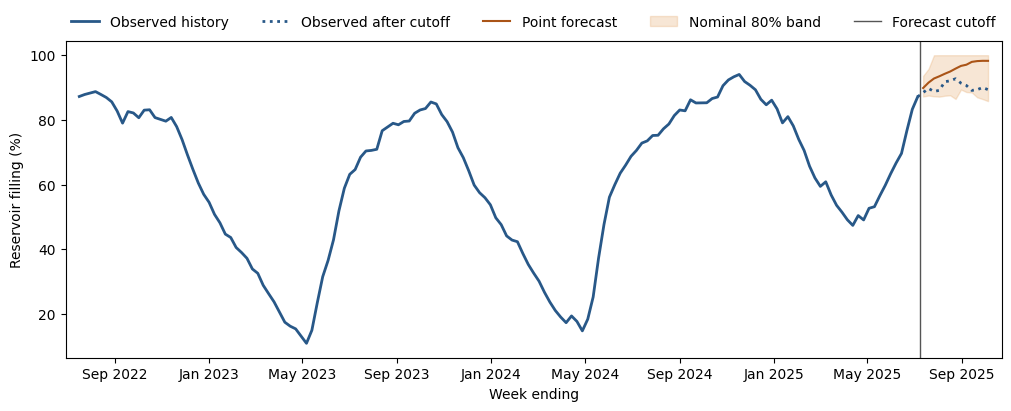

In [ ]:
# The held-out dates enter only after selecting settings on the tuning dates.
test_dates = forecast_dates(2025)
holdout = evaluate(test_dates, winner.Order, int(winner.Weeks), winner.Inputs, bands=True)
scored = holdout.dropna(subset=["actual"])
scored_band = scored.dropna(subset=["lower", "upper"])
covered = scored_band.actual.between(scored_band.lower, scored_band.upper)
metrics = pd.DataFrame(
    [scores(scored, "median"), scores(scored, "seasonal_naive")],
    columns=["MAE (pp)", "RMSE (pp)"], index=["River SNARIMAX", "Seasonal naive"],
)
display(metrics.round(2))
mean_width = (scored_band.upper - scored_band.lower).mean()
print(f"Nominal 80% band: {covered.mean():.1%} coverage across {len(scored_band)} predictions, "
      f"mean width {mean_width:.1f} pp.")
print(f"Historical errors per displayed bound: {scored_band.interval_samples.min()}–"
      f"{scored_band.interval_samples.max()}. "
      f"Median interval-fit runtime: {scored.runtime_ms.median():.1f} ms.")

# Show the full training window and the observations that followed the cutoff.
example = holdout.loc[holdout.origin.eq(test_dates[2])]
training_start = example.index[0] - int(winner.Weeks) * WEEK
observed_weeks = pd.date_range(training_start, example.index[-1], freq="W-SUN")
observed = filling.reindex(observed_weeks)

from matplotlib.dates import DateFormatter, MonthLocator

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
# Repeat the last training observation so the two line segments join.
training_end = example.index[0] - WEEK
observed_history = observed.loc[:training_end]
observed_after_cutoff = observed.loc[training_end:]
ax.plot(observed_history.index, observed_history, label="Observed history", color="#285888", linewidth=2)
ax.plot(observed_after_cutoff.index, observed_after_cutoff, label="Observed after cutoff",
        color="#285888", linestyle=":", linewidth=2)
ax.plot(example.index, example["median"], label="Point forecast", color="#aa5417")
ax.fill_between(example.index, example.lower, example.upper, alpha=0.22,
                color="#df9142", label="Nominal 80% band")
ax.axvline(test_dates[2], color="#555555", linewidth=1, label="Forecast cutoff")
ax.set(ylabel="Reservoir filling (%)", xlabel="Week ending")
ax.xaxis.set_major_locator(MonthLocator(bymonth=(1, 5, 9)))
ax.xaxis.set_major_formatter(DateFormatter("%b %Y"))
ax.margins(x=0.015)
# Distribute the legend across the axes so it fits without squeezing the plot.
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.02, 1, 0), mode="expand",
          ncol=5, frameon=False, borderaxespad=0)
plt.show()

## Map boundaries, transfers, and weather

I export simplified boundaries for the Streamlit map and group NVE regions to approximate the three water areas. I check how temperature and precipitation relate to weekly filling changes and whether weather measured earlier has a stronger relationship. I also compare forecasts with and without weather or net flow. For NO3, I test each connected border and the sum across the selected links on the same dates.

In [ ]:
# Export and count the map shapes by area type.
geometry_path = root / "data" / "reservoir_areas.geojson"
export_reservoir_geojson(geometry_path)
geometry = json.loads(geometry_path.read_text())
area_types = [feature["properties"]["area_type"] for feature in geometry["features"]]
display(pd.Series(area_types).value_counts())

# Use the same dates and training length for each net-flow comparison.
optional_dates = pd.to_datetime(["2025-07-30", "2025-08-27", "2025-09-24"]).tolist()
optional_training_weeks = 78
net_flows = {border: flow} if not flow.empty else {}
domestic_links = ("NO1–NO3", "NO3–NO4", "NO3–NO5")
try:
    for connection in domestic_links:
        weekly = query_weekly_flows(connection, pd.Timestamp("2024-01-01"), pd.Timestamp("2025-12-31"))
        if not weekly.empty:
            net_flows[connection] = weekly
except PyMongoError:
    print("Archived domestic flows could not be read from MongoDB.")

# Orient every series as net flow into NO3. For the total, require all four links.
transfer_cases = {"NVE only": (), **{f"NVE and {link}": (link,) for link in net_flows}}
if len(net_flows) == 4:
    transfer_cases["NVE and all four NO3 links"] = tuple(net_flows)
optional_scores = []
for name, links in transfer_cases.items():
    inputs = ()
    if links:
        sources["net_import_mwh"] = combine_net_flows({link: net_flows[link] for link in links}, "NO3")
        inputs = ("net_import_mwh",)
    try:
        forecasts = evaluate(optional_dates, winner.Order, optional_training_weeks, inputs)
    except ValueError as error:
        print(f"{name} could not be scored: {error}")
    else:
        optional_scores.append((name, *scores(forecasts, "median")))
display(pd.DataFrame(optional_scores, columns=["Input comparison", "MAE (pp)", "RMSE (pp)"]).round(2))

EL      5
VASS    3
NO      1
Name: count, dtype: int64

,Input comparison,MAE (pp),RMSE (pp)
0,NVE only,4.70,6.48
1,NVE and NO3–SE2,7.01,8.81
2,NVE and NO1–NO3,6.07,8.00
3,NVE and NO3–NO4,4.68,6.24
4,NVE and NO3–NO5,6.04,8.63
5,NVE and all four NO3 links,5.08,7.23


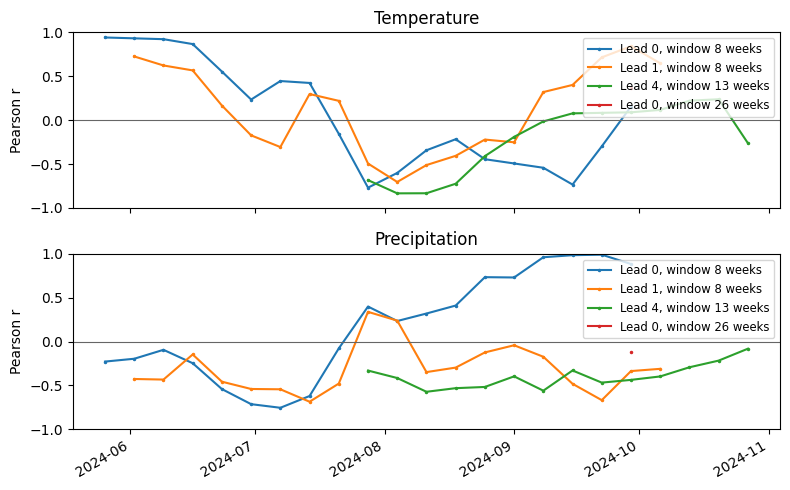

,Weather,Lead,Window,Windows observed,Min r,Max r
0,Temperature,0,8,19,-0.77,0.94
1,Temperature,1,8,19,-0.70,0.84
2,Temperature,4,13,14,-0.83,0.24
3,Temperature,0,26,1,0.37,0.37
4,Precipitation,0,8,19,-0.75,0.99
5,Precipitation,1,8,19,-0.69,0.34
6,Precipitation,4,13,14,-0.57,-0.08
7,Precipitation,0,26,1,-0.11,-0.11


In [ ]:
# Use a shorter period to limit the number of weather downloads.
try:
    area_hourly = fetch_weather("NO3", "2024-03-25", "2024-10-01")
    area_weeks = weekly_weather(area_hourly)
except requests.RequestException as error:
    area_weeks = pd.DataFrame()
    print(f"NO3 weather download incomplete ({type(error).__name__}). Cached cells can be reused.")
if not area_weeks.empty:
    fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, sharey=True)
    summaries = []
    weather_labels = {"temperature_2m": "Temperature", "precipitation": "Precipitation"}
    for ax, (feature, label) in zip(axes, weather_labels.items()):
        for lead, window in [(0, 8), (1, 8), (4, 13), (0, 26)]:
            correlation = rolling_weather_correlation(filling, area_weeks[feature], lead, window).dropna()
            if correlation.empty:
                continue
            ax.plot(correlation.index, correlation,
                    label=f"Lead {lead}, window {window} weeks", marker=".", ms=3)
            summaries.append((label, lead, window, len(correlation), correlation.min(), correlation.max()))
        ax.set(title=label, ylabel="Pearson r", ylim=(-1, 1))
        ax.axhline(0, color="#666", lw=0.8)
        ax.legend(fontsize="small", loc="upper right")
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()
    correlation_summary = pd.DataFrame(summaries,
        columns=["Weather", "Lead", "Window", "Windows observed", "Min r", "Max r"])
    display(correlation_summary.round(2))

In [ ]:
# Reuse the weekly weather cache to avoid rebuilding the training history.
first, last = pd.Timestamp("2024-01-21"), pd.Timestamp("2025-09-21")
weather_cache = root / ".local" / "part4-weather-training.csv"
try:
    if weather_cache.is_file():
        weather_fit = pd.read_csv(weather_cache, index_col="week", parse_dates=["week"])
        weather_fit["available_at"] = pd.to_datetime(weather_fit.available_at, utc=True)
    else:
        blocks = [
            (first, pd.Timestamp("2024-12-29")),
            (pd.Timestamp("2025-01-05"), last),
        ]
        weather_fit = pd.concat([weather_week_range("NO3", a, b) for a, b in blocks])
        weather_fit.to_csv(weather_cache)
    weather_inputs = ("temperature_2m", "precipitation")
    for feature in weather_inputs:
        sources[feature] = weather_fit

    comparison = []
    for inputs in [(), weather_inputs]:
        forecasts = evaluate(optional_dates, winner.Order, optional_training_weeks, inputs)
        label = " + ".join(inputs) or "NVE only"
        comparison.append((label, *scores(forecasts, "median")))
    display(pd.DataFrame(comparison, columns=["Inputs", "MAE (pp)", "RMSE (pp)"]).round(2))
except (requests.RequestException, ValueError) as error:
    print(f"Optional weather comparison could not run for {first.date()} through {last.date()}.")
    print(type(error).__name__, "· Cached ERA5 cells are reused on the next run.")

,Inputs,MAE (pp),RMSE (pp)
0,NVE only,3.96,5.00
1,temperature_2m + precipitation,4.07,5.16


## Compulsory work log

I sketched the three Streamlit pages before building them. Map & Overview and Forecast share the area and historical dates, so I can switch between them without making those selections again. I set the forecast horizon on the Forecast page. Explore & Quality keeps the same area and has its own analysis controls. I put the history chart next to the NVE table so I could look up any odd values in the original records. I labeled the water areas as approximate on the map because I grouped NVE administrative regions to draw them. Those boundaries also affect the weather averages.

Before joining the data in Jupyter, I checked what each timestamp meant. NVE publishes reservoir filling after the week ends. ENTSO-E uses UTC intervals, and each ERA5 precipitation reading covers the previous hour. Norges Bank publishes exchange rates on business days. Easter gave me a chance to check both the clock change and the gaps in exchange rates over the holidays. I used estimated publication times to decide what data would have been available for each forecast, since the historical records can include later revisions.

I ran 13-week forecasts from several dates in the past and timed them as well as checking the errors. The seasonal-naive forecast, which uses filling from the same week a year earlier, had the lowest error on the 2023 and 2024 tuning dates. On the 2025 test dates, River SNARIMAX had a mean absolute error of 4.86 percentage points, compared with 16.72 for the seasonal-naive forecast. For the Streamlit default, I picked the River settings with the lowest tuning error. The model uses 156 weeks of history, order `(1, 1, 0)`, a 52-week seasonal lag, and reservoir filling as its only input. I used River's quantile loss on past errors to estimate the nominal 80% prediction band. It covered 96.2% of the 52 test observations and was 21.3 percentage points wide on average.

In the notebook I could check coverage and try different weather lags. For NO3 in 2024, the 8-week temperature correlation with no lag ranged from −0.77 to 0.94. The 26-week window gave me just one estimate. I compared forecast errors on the same dates to see whether adding weather helped. In Streamlit, I spent time on chart labels, messages for missing data, and keeping selections when switching pages. Caching the weather files meant I could try different dates without downloading the same data again.

[Public GitHub repository](https://github.com/dared22/ind320) ·
[Streamlit app](https://cklqlkatpe9mqyrnuch2ma.streamlit.app/) ·
[Video Walkthrough](https://drive.google.com/file/d/1zyzuYom414O-E19M3-ZTKzRUSJUEafsK/view?usp=sharing)

### My Streamlit sketches

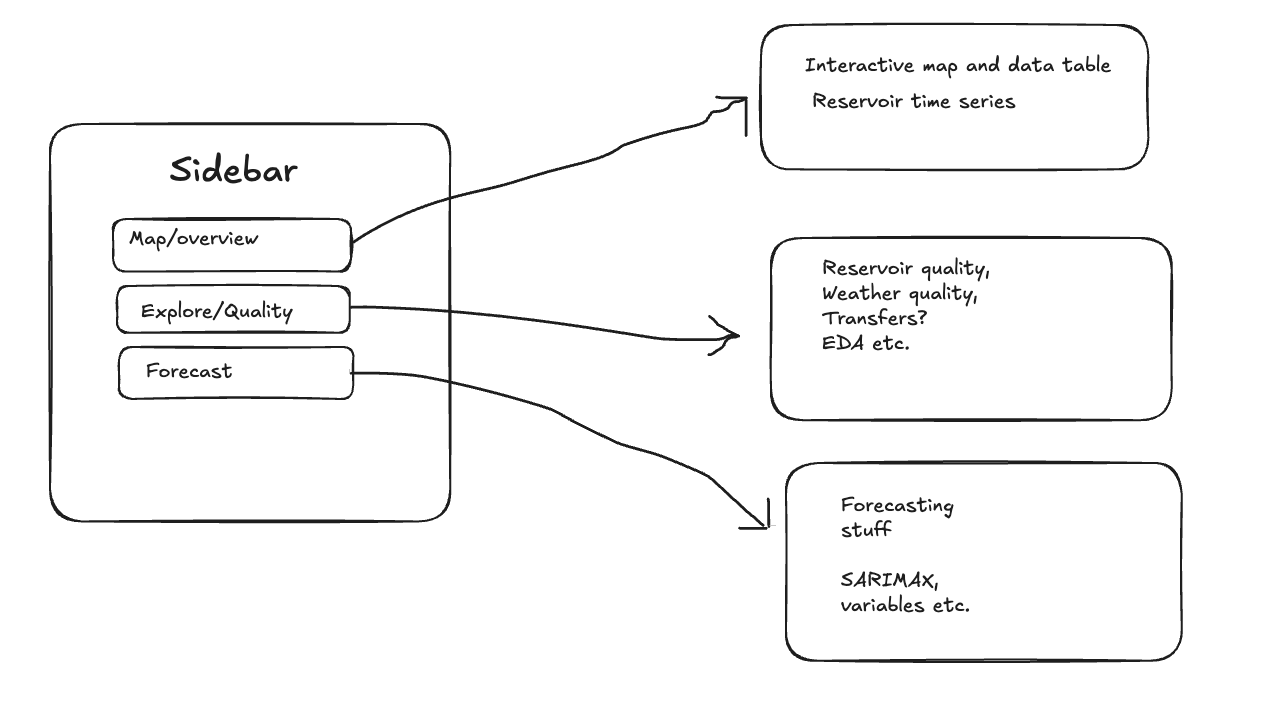

*Sidebar navigation and what goes on each page.*

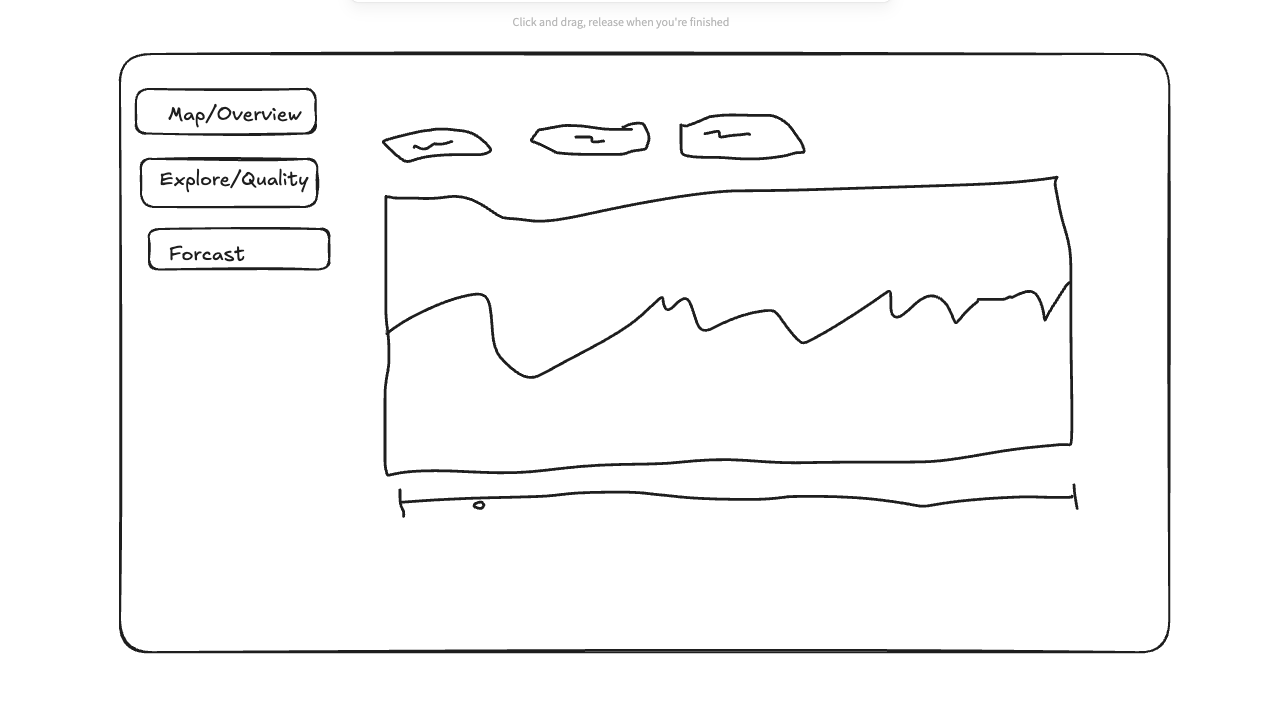

*Forecast page layout.*

## AI-tool use

I used AI to help develop and revise the API code, shared analysis functions,
Streamlit controls, documentation and regression checks. After peer feedback,
AI also helped replace single-point weather with sample-weighted area averages,
synchronize area selection, remove filtered SPC curves and reorganize notebooks.
I remain responsible for understanding the methods, checking results and
verifying the final submission. Automated checks with simulated API responses
verify behavior; they do not replace rerunning the notebook with live data.